A team possession links verified successful-pass player segments; a pass can change the carrier while retaining the team key. A terminal event or unverified link ends this reconstructed interval. Individual control, canonical actions and the analysis sampling are separate units. Any usable frame remains queryable. **design choice**

## Implemented segmentation policy

The active sibling pipeline is `skillcorner-analysis/scripts/pipeline/rebuild_base.py`, using `scripts/utils/base_pipeline.py`. It keeps matched individual boundaries and native tracking geometry. Drives are anchored to individual starts in one-second blocks. All failures remain, including short ones. Passes are instantaneous at release, with previous action equal to the start type before one second of control, otherwise drive.

Short non-loss tails enter drive-rate training as observed exposure, with a survival contribution to their actual duration. They never become successful-at-one-second action-choice labels. Shot, foul suffered and clearance preserve preceding drives and add terminal evaluation snapshots. This is the project's convention; Fernández specifies the split of long drives, without a complete rule for partial tails [@fernandez2021].

| Ending | Canonical times (s) | Additional snapshots (s) |
|---|---|---|
| Pass at 0.4 | 0.4 | 0 |
| Pass at 2.4 | 0; 1; 2.4 | 2 |
| Clearance at 1.4 | 0 | 1; 1.4 |

For clearance at 1.4, 0–1 is a successful canonical drive; 1–1.4 is 0.4 seconds without drive loss. The full drive is eligible for the optional residual training, labeled final individual loss because of clearance; the short tail is excluded there. Clearance itself is outside the binary pass/drive choice.

`get_checkpoints()` selects canonical rows; `include_snapshots=True` includes extras. `compute_possession()` evaluates both by default and marks their roles. Extra overlapping forecasts must not be inserted into survival. Even canonical aggregation needs coherent conditional targets before being interpreted probabilistically. `time_since_start` remains excluded from core action-selection features. See [pipeline layout](../../pipeline.qmd) and [interpretation](../../interpretation.qmd).

## Usage and visual

The following inputs are deterministic and synthetic. No real match rows are embedded.

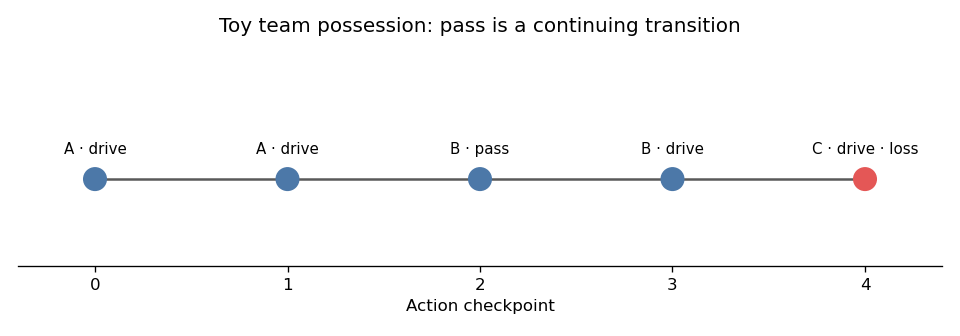

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Toy team sequence: successful passes change the carrier, not the team-possession ID.
checkpoints=np.arange(5); carriers=["A","A","B","B","C"]; actions=["drive","drive","pass","drive","drive"]; terminal_loss=[False,False,False,False,True]
fig,ax=plt.subplots(figsize=(8,2.8)); ax.hlines(0,0,4,color="0.35"); ax.scatter(checkpoints,np.zeros(5),s=180,c=["#4c78a8" if not l else "#e45756" for l in terminal_loss],zorder=3)
for x,c,a,l in zip(checkpoints,carriers,actions,terminal_loss): ax.annotate(f"{c} · {a}"+(" · loss" if l else ""),(x,0),xytext=(0,15),textcoords="offset points",ha="center",fontsize=9)
ax.set(ylim=(-.35,.55),xlim=(-.4,4.4),yticks=[],xlabel="Action checkpoint",title="Toy team possession: pass is a continuing transition"); ax.spines[["left","right","top"]].set_visible(False); fig.tight_layout()
out=Path("figures/vignette_06_possession_setup.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))

## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../usage.qmd) to use processed local files.


In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
print(model.get_possessions().to_string(index=False))
print(model.get_frames(possession_id)[["frame", "player_possession"]].to_string(index=False))
print(model.get_checkpoints(possession_id)[["frame_id", "start_type_std", "previous_action_std"]].to_string(index=False))
print("selected state carrier:", model.get_state(frame_id)["player"])

print("context inside an action:", model.get_frame_context(frame_id))
print("alternative frame selection:", model.get_frames(possession_id, valid_only=True).frame.iloc[5::10].to_list())
assert frame_id not in model.get_checkpoints(possession_id).frame_id.to_list()


 possession_id team_id  frame_start  frame_end  lost
             1    home            0         29  True
             2    away           30         39 False
 frame player_possession
     0            home_7
     1            home_7
     2            home_7
     3            home_7
     4            home_7
     5            home_7
     6            home_7
     7            home_7
     8            home_7
     9            home_7
    10            home_8
    11            home_8
    12            home_8
    13            home_8
    14            home_8
    15            home_8
    16            home_8
    17            home_8
    18            home_8
    19            home_8
    20            home_8
    21            home_8
    22            home_8
    23            home_8
    24            home_8
    25            home_8
    26            home_8
    27            home_8
    28            home_8
    29            home_8
 frame_id      start_type_std previous_action_std
        0 recept

## Observation frames and canonical steps

The extended Fernandez framework defines the drive action over one second [@fernandez2021]. Frame-level inference can be performed anywhere; a retrospective survival interpretation additionally requires successive canonical risk steps. The source pipeline's shared boundaries and final partial intervals are project conventions to audit. The local estimate remains forward-looking even when evaluated on a replay. See [interpretation](../../interpretation.qmd). **model scope**

## Executable clearance at 1.4 seconds

This synthetic 10 Hz interval shows the three evaluation times and their roles. The forecast horizon stays one second; the 0.4-second tail is a training exposure, not a shorter candidate in action selection.

In [8]:
import pandas as pd
tracking, possessions, _, xT_grid = load_demo_match()
tracking["player_possession"] = "home_7"
possessions = possessions.iloc[[0]].copy()
possessions["frame_end"] = 14
rows = pd.DataFrame([
    dict(frame_start=0, frame_end=10, action="ball_drive", is_canonical=True,
         previous_action="pass_reception"),
    dict(frame_start=10, frame_end=14, action="snapshot", is_canonical=False,
         previous_action="ball_drive", snapshot_reason="short_control_tail"),
    dict(frame_start=14, frame_end=14, action="snapshot", is_canonical=False,
         previous_action="ball_drive", snapshot_reason="terminal_clearance"),
])
rows["start_type"] = "pass_reception"
clearance = PRESS(tracking, possessions_data=possessions, actions_data=rows)
print("canonical frames:", clearance.get_checkpoints(1).frame_id.to_list())
profile = clearance.compute_possession(1, xT_grid,
    ppcf_kwargs={"r_max": 12, "step": 6}, bcos_kwargs={"r_max": 8, "step": 4})
print(profile[["frame_id", "checkpoint_kind", "is_canonical", "Hazard"]].to_string(index=False))
assert profile.frame_id.to_list() == [0, 10, 14]
assert profile.is_canonical.to_list() == [True, False, False]

canonical frames: [0]
 frame_id checkpoint_kind  is_canonical   Hazard
        0       canonical          True 0.015078
       10        snapshot         False 0.008789
       14        snapshot         False 0.008596
